
# Chapter 7
## How to Picture Neural Networks: In Your Head and on Paper

**Reference:** *Grokking Deep Learning* — Andrew W. Trask

This chapter explains how to simplify and visualize neural networks so that their behavior becomes easier to understand.

Topics include correlation summarization, simplified network diagrams, forward propagation, representing variables with letters, and using visualization tools to understand neural network operations.


In [1]:

import numpy as np

np.random.seed(1)

print("NumPy version:", np.__version__)
print("Libraries imported successfully.")


NumPy version: 2.1.3
Libraries imported successfully.



## Correlation Summarization

One central idea in neural networks is that they learn relationships between input data and target outputs.

During training, the network adjusts its weights to reduce prediction error. These adjustments help the model identify patterns in the input that are useful for predicting the target.

Correlation summarization is a way to mentally simplify the many operations inside a neural network into the broader idea of discovering and learning relationships in data.


In [2]:

# Example input data and target values
inputs = np.array([1, 2, 3, 4, 5])
targets = np.array([2, 4, 6, 8, 10])

correlation = np.corrcoef(inputs, targets)[0, 1]

print("Inputs:", inputs)
print("Targets:", targets)
print("Correlation:", correlation)


Inputs: [1 2 3 4 5]
Targets: [ 2  4  6  8 10]
Correlation: 0.9999999999999999



## Simplified Visualization

A neural network can be represented as a sequence of connected layers.

- **Input layer:** receives the input features.
- **Hidden layer:** transforms the inputs into intermediate representations.
- **Output layer:** produces the final prediction.

Weights connect the layers and determine how information is transformed as it passes through the network.

This simplified representation makes it easier to reason about the overall flow of information.


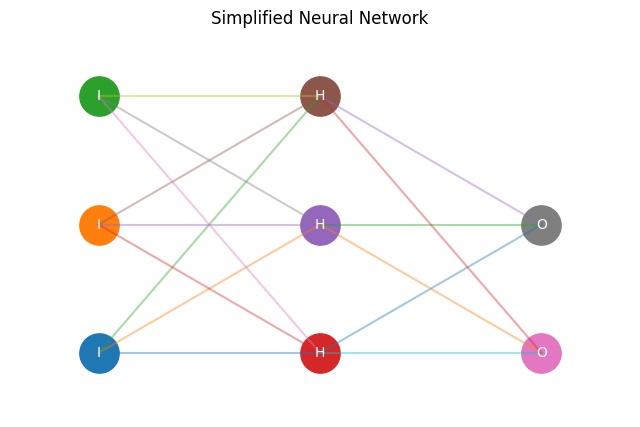

In [3]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))

layers = {
    "Input": [(0, 0), (0, 1), (0, 2)],
    "Hidden": [(1, 0), (1, 1), (1, 2)],
    "Output": [(2, 0), (2, 1)]
}

for name, nodes in layers.items():
    for x, y in nodes:
        ax.scatter(x, y, s=800)
        ax.text(x, y, name[0], ha="center", va="center",
                color="white", fontsize=10)

for x1, y1 in layers["Input"]:
    for x2, y2 in layers["Hidden"]:
        ax.plot([x1, x2], [y1, y2], alpha=0.4)

for x1, y1 in layers["Hidden"]:
    for x2, y2 in layers["Output"]:
        ax.plot([x1, x2], [y1, y2], alpha=0.4)

ax.set_title("Simplified Neural Network")
ax.set_xlim(-0.4, 2.4)
ax.set_ylim(-0.5, 2.5)
ax.axis("off")
plt.show()



## Seeing the Network Predict

During forward propagation, information travels from the input layer through the hidden layer and toward the output layer.

Each layer performs calculations using its inputs and weights. The resulting values become the inputs to the next layer.

The final output represents the network's prediction. Comparing this prediction with the target makes it possible to calculate the error used during training.


In [4]:

inputs = np.array([[0.5, 0.8]])

weights_0 = np.array([
    [0.2, 0.4, 0.6],
    [0.1, 0.3, 0.5]
])

weights_1 = np.array([
    [0.3, 0.7],
    [0.2, 0.4],
    [0.6, 0.8]
])


def relu(x):
    return np.maximum(0, x)


hidden = relu(inputs.dot(weights_0))
prediction = hidden.dot(weights_1)

print("Input:", inputs)
print("Hidden layer:", hidden)
print("Prediction:", prediction)


Input: [[0.5 0.8]]
Hidden layer: [[0.18 0.44 0.7 ]]
Prediction: [[0.562 0.862]]



## Visualizing Using Letters Instead of Pictures

A neural network can also be represented using variables rather than diagrams.

For example, let l0 represent the input, W0 represent the first weight matrix, and W1 represent the second weight matrix.

The hidden layer and output can then be expressed mathematically. This notation makes it easier to follow the calculations without drawing every neuron and connection.



## Linking the Variables

The variables in a neural network are connected through mathematical operations.

For a network with one hidden layer, the input is multiplied by the first weight matrix to calculate the hidden representation. An activation function can then be applied before the result is multiplied by the second weight matrix.

The notation makes the relationships between inputs, weights, hidden representations, and outputs explicit.


In [5]:

l0 = np.array([[0.5, 0.8]])

W0 = np.array([
    [0.2, 0.4, 0.6],
    [0.1, 0.3, 0.5]
])

W1 = np.array([
    [0.3, 0.7],
    [0.2, 0.4],
    [0.6, 0.8]
])

l1 = np.maximum(0, l0.dot(W0))
l2 = l1.dot(W1)

print("l0 (input):\n", l0)
print("l1 (hidden):\n", l1)
print("l2 (output):\n", l2)


l0 (input):
 [[0.5 0.8]]
l1 (hidden):
 [[0.18 0.44 0.7 ]]
l2 (output):
 [[0.562 0.862]]



## Understanding Weight Connections

Each weight determines how strongly one value contributes to a neuron in the next layer.

A weight matrix represents the connections between two layers. Matrix multiplication combines the incoming values with the corresponding weights to produce the next representation.

During training, these weights are adjusted to improve the network's predictions.


In [6]:

print("First weight matrix W0:")
print(W0)

print("\nSecond weight matrix W1:")
print(W1)

print("\nShape of W0:", W0.shape)
print("Shape of W1:", W1.shape)


First weight matrix W0:
[[0.2 0.4 0.6]
 [0.1 0.3 0.5]]

Second weight matrix W1:
[[0.3 0.7]
 [0.2 0.4]
 [0.6 0.8]]

Shape of W0: (2, 3)
Shape of W1: (3, 2)



## The Importance of Visualization Tools

Visualization tools help make the structure and behavior of a neural network easier to understand.

Diagrams can show how layers connect, while numerical outputs can reveal how values change during forward propagation.

Visualizing intermediate calculations is also useful for debugging shape mismatches, incorrect operations, and unexpected predictions.


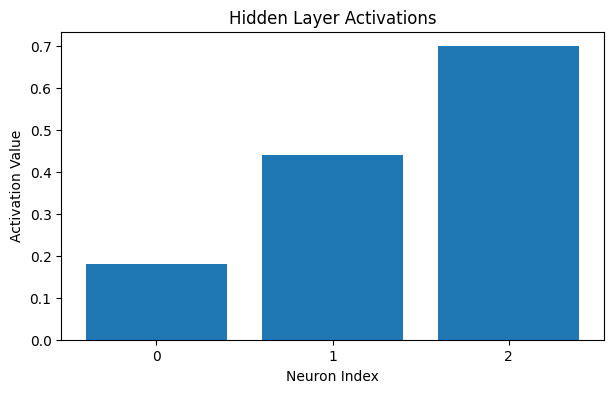

In [7]:

plt.figure(figsize=(7, 4))

plt.bar(
    range(l1.shape[1]),
    l1[0]
)

plt.title("Hidden Layer Activations")
plt.xlabel("Neuron Index")
plt.ylabel("Activation Value")
plt.xticks(range(l1.shape[1]))
plt.show()


In [8]:

print("Input values:")
print(l0)

print("\nHidden representation:")
print(l1)

print("\nFinal prediction:")
print(l2)

print("\nInput shape:", l0.shape)
print("Hidden shape:", l1.shape)
print("Output shape:", l2.shape)


Input values:
[[0.5 0.8]]

Hidden representation:
[[0.18 0.44 0.7 ]]

Final prediction:
[[0.562 0.862]]

Input shape: (1, 2)
Hidden shape: (1, 3)
Output shape: (1, 2)



## Key Concepts Review

- Neural networks learn useful relationships between inputs and targets.
- Correlation summarization provides a simplified mental model of learning.
- Network diagrams show how information flows through connected layers.
- Mathematical notation makes the relationships between variables easier to follow.
- Visualization helps explain intermediate activations and debug neural network calculations.



## Summary

This chapter focused on simplifying the way neural networks are understood and visualized.

We explored correlation summarization, simplified network diagrams, forward propagation, and the use of mathematical variables to represent connected layers.

We also used Python and NumPy to inspect the intermediate calculations of a small neural network and used visualization to examine its structure and activations.

The main lesson is that understanding the overall relationships between inputs, weights, layers, and outputs makes it easier to design, debug, and explain neural networks.
